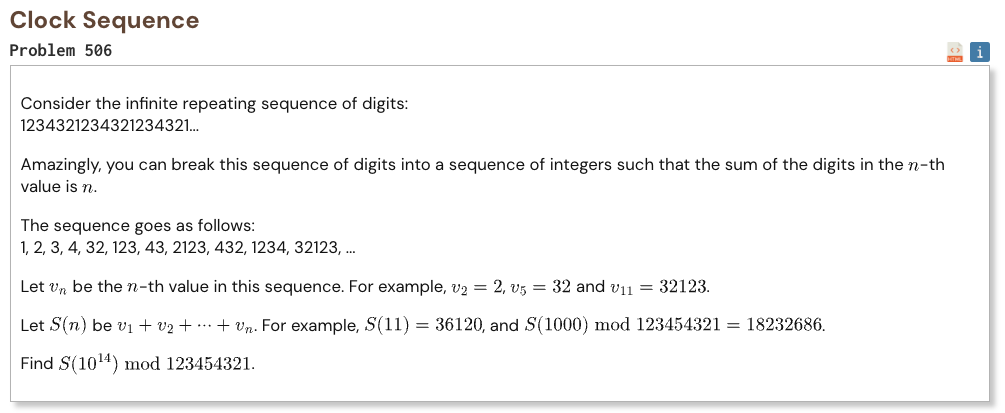

## Initial approach

- the pattern of values repeats every 15 terms
- moving 15 terms forward adds one extra six digit block
- this gives a simple recurrence for each of the 15 repeating positions
- generate only the first 30 values to discover the 15 recurrence constants
- sum each repeating position with fast geometric series calculations
- combine the 15 sums modulo 123454321

In [1]:
%%time

MOD = 123454321
N = 10**14

digits = (1, 2, 3, 4, 3, 2)

def first_values(n):
    position = 0
    values = []

    for target in range(1, n + 1):
        digit_sum = 0
        value = 0

        while digit_sum < target:
            digit = digits[position]
            position = (position + 1) % 6

            digit_sum += digit
            value = value * 10 + digit

        values.append(value)

    return values

def power_sums(base, n):
    if n == 0:
        return 1, 0, 0

    if n == 1:
        return base % MOD, 1, 0

    if n % 2 == 0:
        power, total, weighted = power_sums(
            base,
            n // 2
        )

        half = n // 2

        return (
            power * power % MOD,
            total * (1 + power) % MOD,
            (
                weighted * (1 + power)
                + power * (half % MOD) * total
            ) % MOD
        )

    power, total, weighted = power_sums(
        base,
        n - 1
    )

    return (
        power * base % MOD,
        (total + power) % MOD,
        (
            weighted
            + ((n - 1) % MOD) * power
        ) % MOD
    )

values = first_values(30)
base = 10**6
result = 0

for r in range(1, 16):
    count = (N - r) // 15 + 1

    first = values[r - 1] % MOD

    constant = (
        values[r + 14]
        - base * values[r - 1]
    ) % MOD

    _, geometric, _ = power_sums(
        base,
        count
    )

    if count == 1:
        accumulated = 0
    else:
        _, total, weighted = power_sums(
            base,
            count - 1
        )

        accumulated = (
            ((count - 1) % MOD) * total
            - weighted
        ) % MOD

    result += (
        first * geometric
        + constant * accumulated
    )

    result %= MOD

print("Result:", result)

Result: 18934502
CPU times: user 1.07 ms, sys: 23 μs, total: 1.09 ms
Wall time: 1.1 ms
